# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [64]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent,EpsilonGreedyAgent,ContextualAgent # add your own agents here

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [8]:
TEAM_LOG_FILES = [
    "fishing_log_liuf.json",
    "fishing_log_rakotova.json",
    "fishing_log_yangz.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
# spots, catches = choices(logs[0], season=1)
print("lol")

lol


## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [17]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

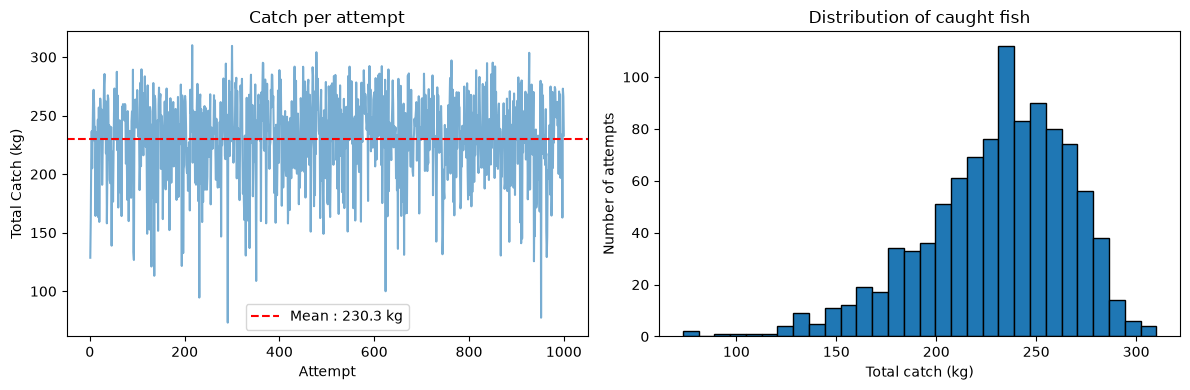

In [31]:
# Your code here

N = 1000
results = []

for seed in range(N):
    bay = FishingBay(season=1, seed=seed)
    agent = EpsilonGreedyAgent(seed=seed,epsilon=0.1)
    results.append(play(agent, bay))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Résultat de chaque essai
axes[0].plot(range(1, N + 1), results, alpha=0.6)
axes[0].axhline(np.mean(results), color="red", linestyle="--",
                label=f"Mean : {np.mean(results):.1f} kg")
axes[0].set(xlabel="Attempt", ylabel="Total Catch (kg)",
            title="Catch per attempt")
axes[0].legend()

# Distribution des résultats
axes[1].hist(results, bins=30, edgecolor="black")
axes[1].set(xlabel="Total catch (kg)", ylabel="Number of attempts",
            title="Distribution of caught fish")

plt.tight_layout()
plt.show()

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [ ]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)

# Your code here

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

In [ ]:
# Your code here

## 4. One parameter

Study the effect of one parameter of one method.

In [ ]:
# Your code here

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [ ]:

N = 1000
results = []
agent = ContextualAgent(seed=0)
for seed in range(N):
    agent.reset()
    bay = ContextualBay(seed=seed)
    total=0
    while not bay.done:
        x = bay.observe_array()                          
        spot =  agent.choose(x)                              
        catch = bay.fish(spot)
        agent.update(spot,catch)
        total+=catch
    results.append(total)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Résultat de chaque essai
axes[0].plot(range(1, N + 1), results, alpha=0.6)
axes[0].axhline(np.mean(results), color="red", linestyle="--",
                label=f"Mean : {np.mean(results):.1f} kg")
axes[0].set(xlabel="Attempt", ylabel="Total Catch (kg)",
            title="Catch per attempt")
axes[0].legend()

# Distribution des résultats
axes[1].hist(results, bins=30, edgecolor="black")
axes[1].set(xlabel="Total catch (kg)", ylabel="Number of attempts",
            title="Distribution of caught fish")

plt.tight_layout()
plt.show()


0 10.3
0 6.9
0 13.5
0 12.1
0 6.9
0 11.5
0 10.3
0 15.7
0 8.9
0 14.6
0 5.5
0 6.7
0 9.5
0 6.6
0 5.3
0 10.4
0 12.1
0 13.7
0 11.9
0 13.2
0 10.4
0 13.3
0 9.9
0 12.0
0 11.5
0 13.0
0 15.9
0 11.3
0 6.3
0 14.8
1 8.4
1 10.8
1 0.4
1 12.6
1 7.8
1 4.0
1 4.9
1 8.4
1 12.4
1 18.2
1 11.1
1 10.8
1 14.3
1 6.9
1 10.0
1 11.8
1 8.3
1 9.1
1 6.7
1 13.7
1 12.5
1 13.3
1 14.0
1 12.5
1 14.7
1 8.8
1 9.6
1 5.4
1 6.7
1 10.2
2 0.0
2 0.0
2 0.0
2 0.0
2 1.2
2 0.5
2 0.0
2 6.2
2 0.5
2 2.4
2 4.2
2 2.0
2 0.0
2 0.0
2 1.3
2 1.5
2 5.9
2 0.0
2 5.6
2 0.0
2 0.6
2 0.3
2 0.0
2 0.0
2 2.5
2 0.0
2 2.4
2 0.0
2 0.0
2 1.5
3 8.6
3 0.0
3 6.0
3 5.3
3 1.9
3 1.1
3 2.0
3 1.6
3 12.2
3 10.5
3 2.6
3 3.7
3 0.0
3 0.0
3 6.0
3 9.8
3 0.0
3 7.3
3 5.9
3 8.7
3 5.0
3 6.5
3 5.7
3 0.0
3 4.5
3 0.8
3 8.1
3 8.2
3 4.1
3 6.4
4 2.7
4 6.3
4 5.7
4 4.1
4 3.4
4 10.7
4 6.3
4 10.8
4 6.0
4 5.6
4 7.3
4 1.6
4 4.6
4 10.2
4 7.2
4 5.4
4 7.1
4 4.0
4 7.9
4 5.1
4 2.2
4 6.6
4 12.0
4 5.7
4 8.2
4 2.7
4 6.6
4 6.5
4 4.5
4 4.2
[{'wind_kmh': 1.1, 'waves_m': 0.4, 'tide_m': 1.3}, {'wind_

TypeError: float() argument must be a string or a real number, not 'dict'